# Pilotage énergétique par RL – 1. Les données

**Le besoin.** Au tarif Tempo, l'heure pleine d'un jour rouge coûte 0,7295 €/kWh, 5,4 fois l'heure creuse d'un jour bleu. Un ballon d'eau chaude et une batterie peuvent décaler de la consommation, à condition de savoir **quand**. On veut un agent qui le décide seul, heure par heure.

**Ce notebook** rassemble les trois sources publiques, vérifie leur qualité et construit le jeu horaire du simulateur (`prepare_data.py`) :

| Source | Contenu | Licence |
|---|---|---|
| UCI (EDF R&D) | conso à la minute d'une maison de Sceaux, déc. 2006 – nov. 2010 | CC BY 4.0 |
| PVGIS (Commission européenne) | production horaire simulée d'un 3 kWc à Sceaux, 2014 – 2023, et température | libre avec citation |
| Jour Tempo (données RTE) | couleur de chaque jour depuis le 01/09/2014 | Licence Ouverte 2.0 |

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from prepare_data import uci_hourly, pvgis_local, DATA
from energy_env import PRIX
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110

brut = pd.read_csv(DATA / "household_power_consumption.txt", sep=";", na_values="?", low_memory=False)
print(f"UCI : {len(brut):,} mesures à la minute, du {brut.Date.iloc[0]} au {brut.Date.iloc[-1]}")
print(f"Valeurs manquantes : {brut.Global_active_power.isna().mean():.2%}")
h = uci_hourly()
print(f"Agrégé à l'heure : {len(h):,} heures")
h.describe().round(1)

UCI : 2,075,259 mesures à la minute, du 16/12/2006 au 26/11/2010
Valeurs manquantes : 1.25%


Agrégé à l'heure : 34,589 heures


,total_wh,ecs_wh,autre_wh
count,34589.0,34589.0,34589.0
mean,1089.0,387.3,701.8
std,896.3,440.7,669.0
min,124.0,0.0,83.4
25%,341.0,39.0,277.2
50%,799.6,99.0,394.8
75%,1577.5,851.0,894.8
max,6560.5,1293.0,5770.0


**Lecture.** 2 075 259 mesures à la minute sur près de 4 ans, avec seulement 1,25 % de trous. Agrégées à l'heure, elles donnent 34 589 heures. Les trous sont bouchés par la même heure de la semaine précédente, puis par interpolation. La maison consomme en moyenne 1,09 kWh par heure, dont 0,39 kWh pour le chauffe-eau.

## 1. Que consomme le chauffe-eau, et quand ?

Le sous-compteur 3 mesure le **chauffe-eau et la climatisation**. C'est notre besoin d'eau chaude. Le reste de la conso (cuisine, buanderie, éclairage, etc.) ne sera pas piloté.

Chauffe-eau : 9.3 kWh/jour en médiane (10e-90e centiles : 4.2 - 14.1)
Part du chauffe-eau dans la conso totale : 36%
Puissance du chauffe-eau quand il chauffe : 1.08 kW (valeur la plus fréquente, en Wh/min x 60)


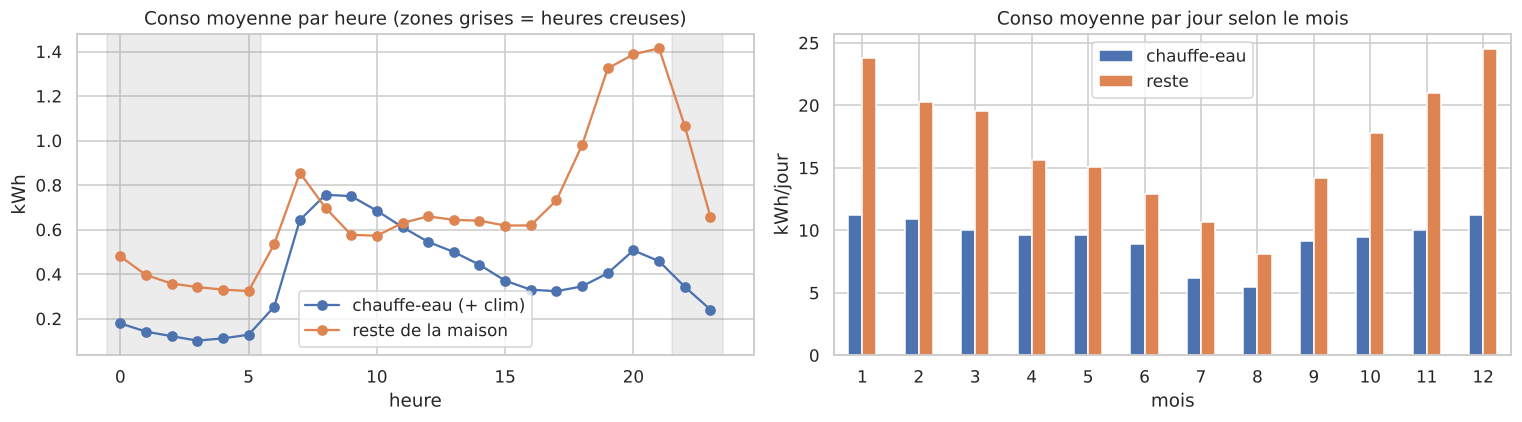

In [2]:
hh = h.copy(); hh["heure"] = hh.index.hour; hh["mois"] = hh.index.month
jour = h.resample("D").sum() / 1000
print(f"Chauffe-eau : {jour.ecs_wh.median():.1f} kWh/jour en médiane (10e-90e centiles : {jour.ecs_wh.quantile(.1):.1f} - {jour.ecs_wh.quantile(.9):.1f})")
print(f"Part du chauffe-eau dans la conso totale : {jour.ecs_wh.sum() / jour.total_wh.sum():.0%}")

brut_sm3 = brut.Sub_metering_3.dropna()
print(f"Puissance du chauffe-eau quand il chauffe : {brut_sm3[brut_sm3 > 10].mode()[0] * 60 / 1000:.2f} kW (valeur la plus fréquente, en Wh/min x 60)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
(hh.groupby("heure")[["ecs_wh", "autre_wh"]].mean() / 1000).plot(ax=axes[0], marker="o")
axes[0].axvspan(-0.5, 5.5, color="grey", alpha=.15); axes[0].axvspan(21.5, 23.5, color="grey", alpha=.15)
axes[0].set(title="Conso moyenne par heure (zones grises = heures creuses)", ylabel="kWh", xlabel="heure")
axes[0].legend(["chauffe-eau (+ clim)", "reste de la maison"])
(hh.groupby("mois")[["ecs_wh", "autre_wh"]].mean() * 24 / 1000).plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Conso moyenne par jour selon le mois", ylabel="kWh/jour"); axes[1].legend(["chauffe-eau", "reste"])
plt.tight_layout(); plt.show()

**Lecture.**
- **Un gros poste flexible :** le chauffe-eau consomme 9,3 kWh par jour en médiane, soit 36 % de la conso de la maison. C'est le gisement à piloter.
- **Il chauffe à la demande :** son pic est entre 7 h et 10 h, juste après les douches, et il ne profite pas des heures creuses (zones grises). C'est la référence « thermostat » du projet.
- **Résistance de 1,08 kW :** c'est la puissance la plus fréquente. Le simulateur suppose un ballon de 300 L à 3 kW, plus classique pour un pilotage en heures creuses (hypothèse documentée).
- **Creux en juillet-août :** probablement les vacances. Le reste de la maison double en hiver.

## 2. Le solaire : combien, et quand ?

Production annuelle (kWh) : {2014: 3367, 2015: 3527, 2016: 3245, 2017: 3357, 2018: 3544, 2019: 3576, 2020: 3656, 2021: 3480, 2022: 3720, 2023: 3432}
Soit 1163 kWh par kWc et par an en moyenne


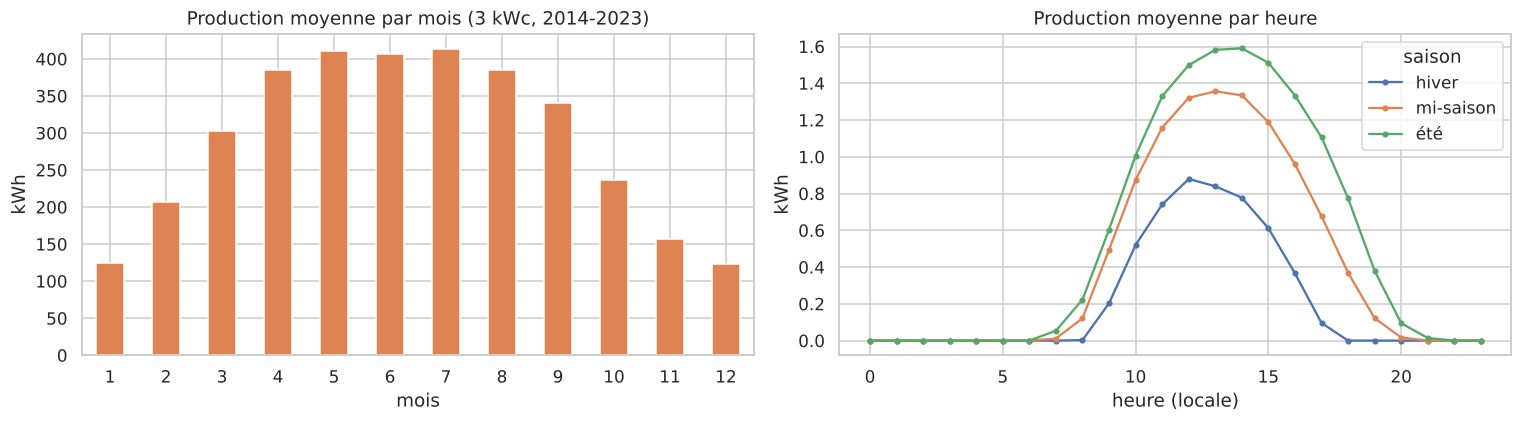

In [3]:
pv = pvgis_local()
an = pv.pv_wh.resample("YE").sum() / 1000
print("Production annuelle (kWh) :", {d.year: int(v) for d, v in an.round(0).items()})
print(f"Soit {an.mean() / 3:.0f} kWh par kWc et par an en moyenne")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
(pv.pv_wh.groupby(pv.index.month).sum() / 1000 / 10).plot.bar(ax=axes[0], rot=0, color="#dd8452")
axes[0].set(title="Production moyenne par mois (3 kWc, 2014-2023)", ylabel="kWh", xlabel="mois")
prof = pv.assign(h=pv.index.hour, saison=np.where(pv.index.month.isin([6, 7, 8]), "été", np.where(pv.index.month.isin([12, 1, 2]), "hiver", "mi-saison")))
(prof.groupby(["h", "saison"]).pv_wh.mean().unstack() / 1000).plot(ax=axes[1], marker=".")
axes[1].set(title="Production moyenne par heure", ylabel="kWh", xlabel="heure (locale)")
plt.tight_layout(); plt.show()

**Lecture.**
- **Production annuelle :** 3 245 à 3 720 kWh selon l'année, soit 1 163 kWh par kWc en moyenne.
- **Saisonnalité forte :** environ 410 kWh par mois de mai à juillet, mais 120 kWh en décembre et janvier, justement les mois des jours rouges.
- **Conséquence pour le pilote :** en été, le levier est de chauffer l'eau à midi avec le solaire ; en hiver, il faut surtout déplacer la conso vers les heures creuses et utiliser la batterie.

## 3. Le tarif Tempo : couleurs et prix

In [4]:
t = pd.read_csv(DATA / "tempo_couleurs.csv", parse_dates=["date"])
t["saison"] = [f"{d.year}-{d.year + 1}" if d.month >= 9 else f"{d.year - 1}-{d.year}" for d in t.date]
cpt = t[t.saison <= "2025-2026"].groupby("saison").couleur.value_counts().unstack()[["bleu", "blanc", "rouge"]]
display(cpt.T)
rouge = t[t.couleur == "rouge"]
print("Mois des jours rouges :", rouge.date.dt.month.value_counts().sort_index().to_dict())
print("Jours de la semaine des jours rouges (0 = lundi) :", rouge.date.dt.dayofweek.value_counts().sort_index().to_dict())

grille = pd.DataFrame({c: {"heures creuses (22h-6h)": PRIX[(c, True)], "heures pleines (6h-22h)": PRIX[(c, False)]} for c in ["bleu", "blanc", "rouge"]})
print("Grille TTC au 1er août 2026 (€/kWh)"); display(grille)

saison,2014-2015,2015-2016,2016-2017,2017-2018,2018-2019,2019-2020,2020-2021,2021-2022,2022-2023,2023-2024,2024-2025,2025-2026
couleur,,,,,,,,,,,,
bleu,300,301,300,300,300,301,300,300,300,301,300,300
blanc,43,43,43,43,43,47,43,43,43,43,43,43
rouge,22,22,22,22,22,18,22,22,22,22,22,22


Mois des jours rouges : {1: 127, 2: 52, 3: 32, 11: 4, 12: 45}
Jours de la semaine des jours rouges (0 = lundi) : {0: 56, 1: 55, 2: 57, 3: 46, 4: 46}
Grille TTC au 1er août 2026 (€/kWh)


,bleu,blanc,rouge
heures creuses (22h-6h),0.1356,0.1536,0.1615
heures pleines (6h-22h),0.1654,0.1921,0.7295


**Lecture.**
- **Saisons régulières :** 300 jours bleus, 43 blancs et 22 rouges chaque saison, sauf 2019-2020 (47 blancs, 18 rouges).
- **Calendrier des jours rouges :** ils tombent de novembre à mars, surtout en janvier (127 sur 260), et jamais le week-end.
- **Écart de prix :** de 0,1356 € (heure creuse bleue) à 0,7295 € (heure pleine rouge), soit 5,4 fois plus cher. En dehors des jours rouges, l'écart entre heures pleines et creuses n'est que de 22 à 25 %.
- **À retenir :** l'essentiel du gain possible se joue sur 22 jours par an, de 6 h à 22 h.

## 4. Le jeu horaire du simulateur

La conso date de 2006-2010, le solaire et Tempo de 2014-2023. `prepare_data.py` **rejoue** chaque jour cible avec le jour UCI de même semaine ISO et de même jour de la semaine, en faisant tourner l'année source (2007, 2008, 2009). Une journée Tempo va de 6 h à 6 h : de 0 h à 6 h, c'est la couleur de la veille qui s'applique. La couleur du lendemain n'est connue qu'à partir de 11 h (publication RTE).

In [5]:
df = pd.read_parquet(DATA / "dataset_horaire.parquet")
print(f"{len(df):,} heures, du {df.index[0]} au {df.index[-1]} ; valeurs manquantes : {int(df.isna().sum().sum())}")
display(df.groupby("saison")[["autre_kwh", "ecs_kwh", "pv_kwh"]].sum().round(0).astype(int))
print("Découpage : entraînement 2014-2015 à 2020-2021, validation 2021-2022, test 2022-2023")
df.head(3)

78,882 heures, du 2014-09-01 06:00:00 au 2023-08-31 23:00:00 ; valeurs manquantes : 0


,autre_kwh,ecs_kwh,pv_kwh
saison,,,
2014-2015,6228,3183,3500
2015-2016,5891,3596,3244
2016-2017,6734,3042,3419
2017-2018,6221,3175,3400
2018-2019,5811,3555,3705
2019-2020,6749,3052,3636
2020-2021,6325,3202,3431
2021-2022,5811,3551,3820
2022-2023,6734,3042,3409


Découpage : entraînement 2014-2015 à 2020-2021, validation 2021-2022, test 2022-2023


,autre_kwh,ecs_kwh,pv_kwh,t2m,tempo,tempo_demain,hc,saison,jour_source_uci
heure,,,,,,,,,
2014-09-01 06:00:00,0.207833,0.091,0.00000,10.80,bleu,inconnu,False,2014-2015,2008-09-01
2014-09-01 07:00:00,0.935667,0.915,0.00000,10.38,bleu,inconnu,False,2014-2015,2008-09-01
2014-09-01 08:00:00,0.722067,1.147,0.15246,10.26,bleu,inconnu,False,2014-2015,2008-09-01


**Lecture.** 78 882 heures sans valeur manquante, de septembre 2014 à août 2023. Selon la saison, la maison consomme 5 800 à 6 750 kWh hors chauffe-eau, et 3 040 à 3 600 kWh pour le chauffe-eau. Le solaire produit 3 240 à 3 820 kWh. La colonne `jour_source_uci` trace le jour réel rejoué. Les saisons 2014-2015 à 2020-2021 servent à l'apprentissage, 2021-2022 au choix du modèle, 2022-2023 au résultat final, jamais vue avant.